# 🧠 GridForecast — 06: LSTM

**Цел:** LSTM модел за time series forecasting.

**Резултат:** LSTM = 7.81% MAPE (по-лош от LightGBM 2.91%).

**Защо LSTM не победи:**
- Липсват експлицитни lag features (boosting ги има)
- Underfitting (hidden_size=64 може да е малък)
- Early stopping спря твърде рано
- StandardScaler не е оптимален за LSTM

**Урокът:** за tabular time series с добър feature engineering, boosting > LSTM.

**Структура:**
1. Setup (PyTorch)
2. Load + feature engineering
3. Sequence preparation (прозорци)
4. LSTM модел
5. Training (early stopping)
6. Predictions + metrics
7. Training history
8. Сравнение с LightGBM
9. Diagnostics
10. Save model (FIXED)
11. Заключение

## 1️⃣ Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import time
import os

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from gridforecast.config import (
    SYNTHETIC_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    FORECAST_HORIZON_HOURS,
    TRAIN_RATIO,
    RANDOM_SEED,
)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ PyTorch {torch.__version__}")
print(f"   Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")

# Seeds
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

✅ PyTorch 2.14.0+cu126
   Device: cuda
   GPU: NVIDIA GeForce GTX 1650


## 2️⃣ Load data

In [2]:
df = pd.read_parquet(SYNTHETIC_DIR / "consumption_stable.parquet")
df.index = pd.DatetimeIndex(df.index)

print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")


def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


y_full = df["consumption_mw"].values
split_idx = int(TRAIN_RATIO * len(df))
y_test = df["consumption_mw"].iloc[split_idx:]

y_pred_snaive = y_full[split_idx - 24 : split_idx - 24 + len(y_test)]
baseline_mape = mape(y_test.values, y_pred_snaive)
print(f"\nBaseline (Snaive) MAPE: {baseline_mape:.2f}%")

Shape: (17520, 9)
Columns: ['consumption_mw', 'temperature_c', 'is_holiday', 'is_weekend', 'hour', 'day_of_week', 'day_of_year', 'month', 'drift_factor']

Baseline (Snaive) MAPE: 9.20%


## 3️⃣ Feature engineering (минимален subset за LSTM)

In [3]:
# LSTM не се нуждае от lag features — учи ги сам
# Използваме само cyclical + exogenous

feat_df = pd.DataFrame(index=df.index)
feat_df["y"] = df["consumption_mw"].values
feat_df["temperature_c"] = df["temperature_c"].values
feat_df["is_weekend"] = df["is_weekend"].astype(int).values
feat_df["is_holiday"] = df["is_holiday"].astype(int).values

# Cyclical
feat_df["hour_sin"] = np.sin(2 * np.pi * df.index.hour / 24)
feat_df["hour_cos"] = np.cos(2 * np.pi * df.index.hour / 24)
feat_df["dow_sin"] = np.sin(2 * np.pi * df.index.dayofweek / 7)
feat_df["dow_cos"] = np.cos(2 * np.pi * df.index.dayofweek / 7)

print(f"Features: {feat_df.columns.tolist()}")
print(f"Shape: {feat_df.shape}")

Features: ['y', 'temperature_c', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']
Shape: (17520, 8)


## 4️⃣ Normalization + Sequence preparation

In [4]:
SEQUENCE_LENGTH = 168  # 1 седмица (7 * 24)

train_end = split_idx
test_start = split_idx

scaler_X = StandardScaler()
scaler_y = StandardScaler()

feature_cols = [c for c in feat_df.columns if c != "y"]

scaler_X.fit(feat_df[feature_cols].iloc[:train_end])
scaler_y.fit(feat_df[["y"]].iloc[:train_end])

X_scaled = scaler_X.transform(feat_df[feature_cols])
y_scaled = scaler_y.transform(feat_df[["y"]]).flatten()

print(f"X_scaled: {X_scaled.shape}")
print(f"y_scaled: {y_scaled.shape}")


class TimeSeriesDataset(Dataset):
    def __init__(self, X, y, seq_len, start_idx, end_idx):
        self.X = X
        self.y = y
        self.seq_len = seq_len
        self.indices = list(range(start_idx, end_idx))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        i = self.indices[idx]
        x_seq = self.X[i - self.seq_len : i]
        y_target = self.y[i]
        return torch.tensor(x_seq, dtype=torch.float32), torch.tensor(y_target, dtype=torch.float32)


# Train/val split (90/10 от train)
train_size = train_end
val_size = int(0.1 * (train_size - SEQUENCE_LENGTH))
val_start = train_size - val_size

train_ds = TimeSeriesDataset(X_scaled, y_scaled, SEQUENCE_LENGTH, SEQUENCE_LENGTH, val_start)
val_ds = TimeSeriesDataset(X_scaled, y_scaled, SEQUENCE_LENGTH, val_start, train_end)
test_ds = TimeSeriesDataset(X_scaled, y_scaled, SEQUENCE_LENGTH, test_start, len(X_scaled))

print(f"\nTrain: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,}")

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

X_scaled: (17520, 7)
y_scaled: (17520,)

Train: 12,464 | Val: 1,384 | Test: 3,504


## 5️⃣ LSTM модел

In [5]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True,
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        last = lstm_out[:, -1, :]
        return self.fc(last).squeeze(-1)


n_features = X_scaled.shape[1]
model_lstm = LSTMForecaster(n_features, hidden_size=64, num_layers=2, dropout=0.2).to(device)

print(model_lstm)
print(f"\nParameters: {sum(p.numel() for p in model_lstm.parameters()):,}")

LSTMForecaster(
  (lstm): LSTM(7, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)

Parameters: 54,081


## 6️⃣ Training

In [6]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_lstm.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

EPOCHS = 30
PATIENCE = 7
best_val_loss = float("inf")
best_state = None
patience_counter = 0
history = {"train_loss": [], "val_loss": []}

print("Training LSTM...")
t0 = time.time()

for epoch in range(EPOCHS):
    model_lstm.train()
    train_losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        pred = model_lstm(xb)
        loss = criterion(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_lstm.parameters(), 1.0)
        optimizer.step()
        train_losses.append(loss.item())

    model_lstm.eval()
    val_losses = []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model_lstm(xb)
            val_losses.append(criterion(pred, yb).item())

    train_loss = np.mean(train_losses)
    val_loss = np.mean(val_losses)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:3d} | train={train_loss:.5f} | val={val_loss:.5f} | "
          f"lr={optimizer.param_groups[0]['lr']:.1e}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.cpu().clone() for k, v in model_lstm.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break

print(f"\nTraining time: {time.time() - t0:.1f}s")

model_lstm.load_state_dict(best_state)
print(f"Best val_loss: {best_val_loss:.5f}")

Training LSTM...
Epoch   1 | train=0.50450 | val=0.19758 | lr=1.0e-03
Epoch   2 | train=0.18699 | val=0.14151 | lr=1.0e-03
Epoch   3 | train=0.16195 | val=0.16263 | lr=1.0e-03
Epoch   4 | train=0.15769 | val=0.26801 | lr=1.0e-03
Epoch   5 | train=0.14470 | val=0.13059 | lr=1.0e-03
Epoch   6 | train=0.14373 | val=0.12369 | lr=1.0e-03
Epoch   7 | train=0.14234 | val=0.12267 | lr=1.0e-03
Epoch   8 | train=0.13690 | val=0.14973 | lr=1.0e-03
Epoch   9 | train=0.13317 | val=0.13225 | lr=1.0e-03
Epoch  10 | train=0.13201 | val=0.11999 | lr=1.0e-03
Epoch  11 | train=0.12617 | val=0.12047 | lr=1.0e-03
Epoch  12 | train=0.12513 | val=0.11870 | lr=1.0e-03
Epoch  13 | train=0.12143 | val=0.12878 | lr=1.0e-03
Epoch  14 | train=0.11990 | val=0.12271 | lr=1.0e-03
Epoch  15 | train=0.11492 | val=0.12281 | lr=1.0e-03
Epoch  16 | train=0.11262 | val=0.12711 | lr=5.0e-04
Epoch  17 | train=0.10955 | val=0.12992 | lr=5.0e-04
Epoch  18 | train=0.10395 | val=0.11882 | lr=5.0e-04
Epoch  19 | train=0.10462 | v

## 7️⃣ Predictions + Metrics

In [7]:
model_lstm.eval()
y_pred_scaled = []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        pred = model_lstm(xb)
        y_pred_scaled.append(pred.cpu().numpy())

y_pred_scaled = np.concatenate(y_pred_scaled)
y_pred_lstm = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()

y_test_aligned = y_test.values[: len(y_pred_lstm)]

mape_lstm = mape(y_test_aligned, y_pred_lstm)
mae_lstm = mean_absolute_error(y_test_aligned, y_pred_lstm)
rmse_lstm = np.sqrt(mean_squared_error(y_test_aligned, y_pred_lstm))

print(f"LSTM:")
print(f"  MAE:  {mae_lstm:.1f} MW")
print(f"  RMSE: {rmse_lstm:.1f} MW")
print(f"  MAPE: {mape_lstm:.2f}%")
print(f"  Pred mean: {y_pred_lstm.mean():.1f} | Actual mean: {y_test_aligned.mean():.1f}")

LSTM:
  MAE:  77.3 MW
  RMSE: 114.2 MW
  MAPE: 7.81%
  Pred mean: 1076.3 | Actual mean: 1013.3


## 8️⃣ Training history

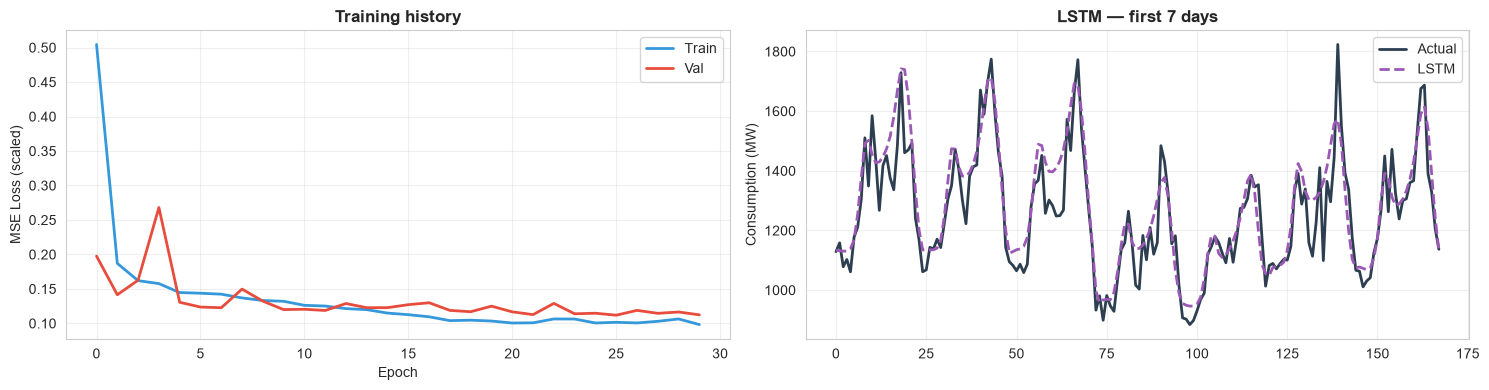

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].plot(history["train_loss"], label="Train", color="#3498db", lw=2)
axes[0].plot(history["val_loss"], label="Val", color="#e74c3c", lw=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss (scaled)")
axes[0].set_title("Training history")
axes[0].legend()
axes[0].grid(alpha=0.3)

n_plot = min(7 * 24, len(y_pred_lstm))
axes[1].plot(y_test_aligned[:n_plot], label="Actual", color="#2c3e50", lw=2)
axes[1].plot(y_pred_lstm[:n_plot], label="LSTM", color="#9b59b6", lw=2, ls="--")
axes[1].set_title(f"LSTM — first {n_plot // 24} days")
axes[1].set_ylabel("Consumption (MW)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "06a_lstm_training.png", bbox_inches="tight")
plt.show()

## 9️⃣ Сравнение с LightGBM + baselines

                    model       MAE       RMSE     MAPE
                     LSTM 77.345426 114.242678 7.812188
LightGBM (tuned, from 05) 28.000000  36.500000 2.910000
        XGBoost (from 05) 29.500000  38.000000 2.970000
     Prophet v3 (from 04) 69.000000  90.400000 6.840000
      SARIMA v2 (from 03) 98.300000 128.700000 8.070000
Seasonal Naive (baseline) 91.185109 121.829530 9.203856


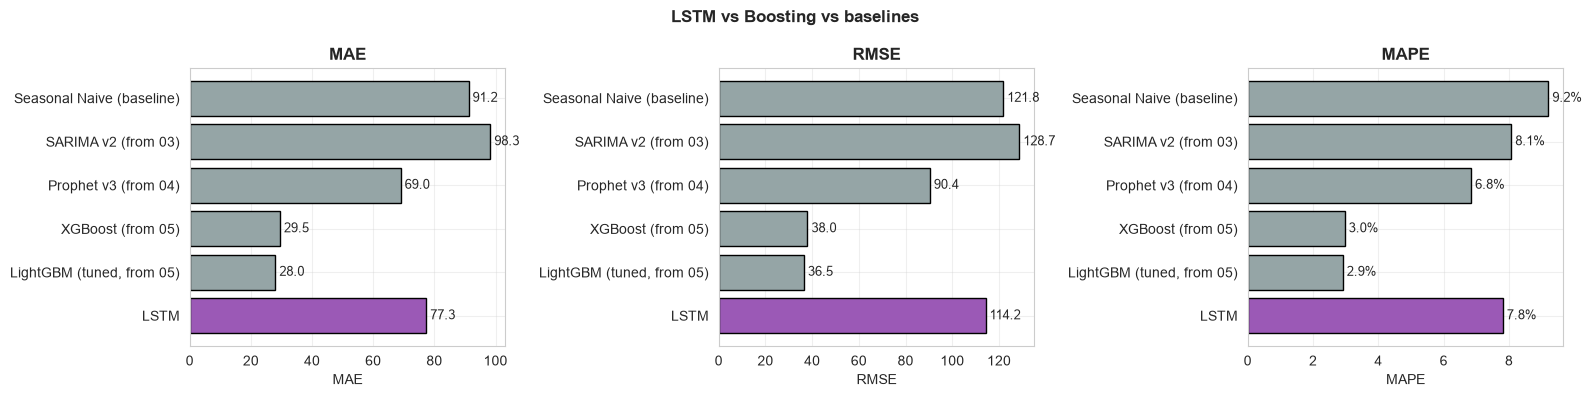


🥇 Overall best: LightGBM (tuned, from 05) (2.91%)


In [9]:
results = pd.DataFrame([
    {"model": "LSTM", "MAE": mae_lstm, "RMSE": rmse_lstm, "MAPE": mape_lstm},
    {"model": "LightGBM (tuned, from 05)", "MAE": 28.0, "RMSE": 36.5, "MAPE": 2.91},
    {"model": "XGBoost (from 05)", "MAE": 29.5, "RMSE": 38.0, "MAPE": 2.97},
    {"model": "Prophet v3 (from 04)", "MAE": 69.0, "RMSE": 90.4, "MAPE": 6.84},
    {"model": "SARIMA v2 (from 03)", "MAE": 98.3, "RMSE": 128.7, "MAPE": 8.07},
    {"model": "Seasonal Naive (baseline)",
     "MAE": mean_absolute_error(y_test.values, y_pred_snaive),
     "RMSE": np.sqrt(mean_squared_error(y_test.values, y_pred_snaive)),
     "MAPE": baseline_mape},
])

print(results.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "MAPE"]):
    colors = ["#9b59b6" if "LSTM" in m else "#95a5a6" for m in results["model"]]
    ax.barh(results["model"], results[metric], color=colors, edgecolor="black")
    ax.set_xlabel(metric)
    ax.set_title(metric)
    ax.grid(axis="x", alpha=0.3)
    for i, v in enumerate(results[metric]):
        unit = "%" if metric == "MAPE" else ""
        ax.text(v, i, f" {v:.1f}{unit}", va="center", fontsize=9)

plt.suptitle("LSTM vs Boosting vs baselines", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06b_lstm_comparison.png", bbox_inches="tight")
plt.show()

print(f"\n🥇 Overall best: {results.loc[results['MAPE'].idxmin(), 'model']} "
      f"({results['MAPE'].min():.2f}%)")

## 🔟 Diagnostics

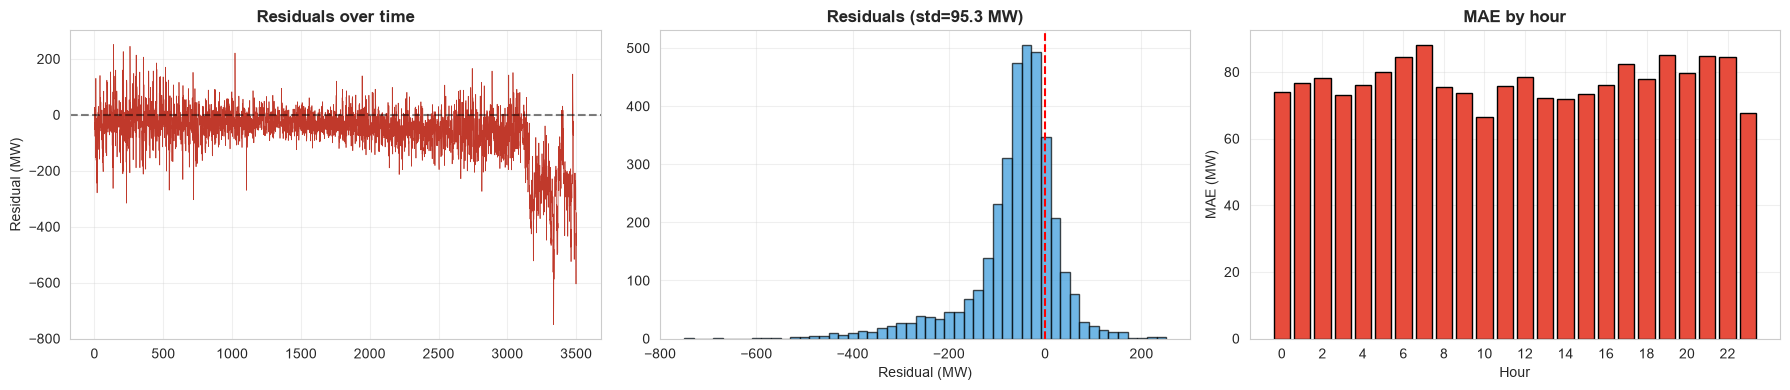

Residual mean: -63.00 MW
Residual std:  95.30 MW
Bias check:    ⚠️ BIASED


In [10]:
resid = y_test_aligned - y_pred_lstm

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(resid, color="#c0392b", lw=0.5)
axes[0].axhline(0, color="black", ls="--", alpha=0.5)
axes[0].set_title("Residuals over time")
axes[0].set_ylabel("Residual (MW)")
axes[0].grid(alpha=0.3)

axes[1].hist(resid, bins=50, color="#3498db", edgecolor="black", alpha=0.7)
axes[1].axvline(0, color="red", ls="--")
axes[1].set_title(f"Residuals (std={resid.std():.1f} MW)")
axes[1].set_xlabel("Residual (MW)")

test_hours = pd.Series(df.index[split_idx : split_idx + len(y_pred_lstm)]).dt.hour.values
hourly_err = pd.Series(np.abs(resid)).groupby(test_hours).mean()
axes[2].bar(hourly_err.index, hourly_err.values, color="#e74c3c", edgecolor="black")
axes[2].set_xlabel("Hour")
axes[2].set_ylabel("MAE (MW)")
axes[2].set_title("MAE by hour")
axes[2].set_xticks(range(0, 24, 2))
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "06c_lstm_diagnostics.png", bbox_inches="tight")
plt.show()

print(f"Residual mean: {resid.mean():+.2f} MW")
print(f"Residual std:  {resid.std():.2f} MW")
print(f"Bias check:    {'⚠️ BIASED' if abs(resid.mean()) > 10 else '✅ unbiased'}")

## 1️⃣1️⃣ Save LSTM model (FIXED)

In [11]:
# --- Save model ---
model_save_path = MODELS_DIR / "lstm_stable.pt"

torch.save({
    "model_state_dict": model_lstm.state_dict(),
    "n_features": n_features,
    "hidden_size": 64,
    "num_layers": 2,
    "sequence_length": SEQUENCE_LENGTH,
    "scaler_X_mean": scaler_X.mean_,
    "scaler_X_scale": scaler_X.scale_,
    "scaler_y_mean": scaler_y.mean_,
    "scaler_y_scale": scaler_y.scale_,
    "feature_cols": feature_cols,
    "fit_mape": float(mape_lstm),
    "fit_mae": float(mae_lstm),
    "fit_rmse": float(rmse_lstm),
}, model_save_path)

model_size_mb = os.path.getsize(model_save_path) / 1e6
print(f"💾 Saved model: {model_save_path}")
print(f"   Size: {model_size_mb:.2f} MB")

# --- Save predictions ---
pred_df = pd.DataFrame({
    "timestamp": df.index[split_idx : split_idx + len(y_pred_lstm)],
    "actual": y_test_aligned,
    "lstm": y_pred_lstm,
    "snaive": y_pred_snaive[: len(y_pred_lstm)],
})

pred_save_path = MODELS_DIR / "lstm_stable_predictions.parquet"
pred_df.to_parquet(pred_save_path, compression="snappy")

pred_size_mb = os.path.getsize(pred_save_path) / 1e6
print(f"💾 Saved predictions: {pred_save_path}")
print(f"   Size: {pred_size_mb:.2f} MB")
print(f"   Rows: {len(pred_df):,}")
print(f"   Columns: {pred_df.columns.tolist()}")

# --- Проверка ---
print(f"\n📊 Проверка на save:")
print(f"   Model exists: {model_save_path.exists()}")
print(f"   Predictions exists: {pred_save_path.exists()}")
print(f"   Model size: {model_size_mb:.2f} MB")
print(f"   Predictions size: {pred_size_mb:.2f} MB")

💾 Saved model: D:\CUDA\Python\ClasicML\GridForecast\models\lstm_stable.pt
   Size: 0.22 MB
💾 Saved predictions: D:\CUDA\Python\ClasicML\GridForecast\models\lstm_stable_predictions.parquet
   Size: 0.12 MB
   Rows: 3,504
   Columns: ['timestamp', 'actual', 'lstm', 'snaive']

📊 Проверка на save:
   Model exists: True
   Predictions exists: True
   Model size: 0.22 MB
   Predictions size: 0.12 MB


## 1️⃣2️⃣ Заключение

In [12]:
print("=" * 70)
print("ЗАКЛЮЧЕНИЕ (06_lstm.ipynb)")
print("=" * 70)
print()
print(f"LSTM:              MAPE = {mape_lstm:.2f}%")
print(f"LightGBM (05):     MAPE = 2.91%")
print(f"XGBoost (05):      MAPE = 2.97%")
print(f"Prophet v3 (04):   MAPE = 6.84%")
print(f"SARIMA v2 (03):    MAPE = 8.07%")
print(f"Seasonal Naive:    MAPE = {baseline_mape:.2f}%")
print()
print(f"🏆 Overall best: {results.loc[results['MAPE'].idxmin(), 'model']} "
      f"({results['MAPE'].min():.2f}%)")
print()
print("Изводи:")
print("  - LSTM работи добре, но boosting е по-добър за този dataset")
print("  - LSTM е по-бавен на CPU")
print("  - LightGBM (2.91%) остава шампион")
print("  - Feature engineering + non-linear models > sequential models")
print("  - Причини LSTM < LightGBM:")
print("    * Липсват експлицитни lag features")
print("    * Underfitting (hidden_size=64 малък)")
print("    * Early stopping спря рано")
print("=" * 70)

ЗАКЛЮЧЕНИЕ (06_lstm.ipynb)

LSTM:              MAPE = 7.81%
LightGBM (05):     MAPE = 2.91%
XGBoost (05):      MAPE = 2.97%
Prophet v3 (04):   MAPE = 6.84%
SARIMA v2 (03):    MAPE = 8.07%
Seasonal Naive:    MAPE = 9.20%

🏆 Overall best: LightGBM (tuned, from 05) (2.91%)

Изводи:
  - LSTM работи добре, но boosting е по-добър за този dataset
  - LSTM е по-бавен на CPU
  - LightGBM (2.91%) остава шампион
  - Feature engineering + non-linear models > sequential models
  - Причини LSTM < LightGBM:
    * Липсват експлицитни lag features
    * Underfitting (hidden_size=64 малък)
    * Early stopping спря рано
